In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv("../dataset/Resume/Resume.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (2484, 4)


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [2]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Column Names:
['ID', 'Resume_str', 'Resume_html', 'Category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB

Missing Values:
ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64


In [3]:

# Check unique job categories

print("Total Job Categories:", df['Category'].nunique())

print("\nAvailable Categories:")
print(df['Category'].unique())

# Count resumes in each category
category_counts = df['Category'].value_counts()

print("\nResume Count by Category:")
print(category_counts)


Total Job Categories: 24

Available Categories:
['HR' 'DESIGNER' 'INFORMATION-TECHNOLOGY' 'TEACHER' 'ADVOCATE'
 'BUSINESS-DEVELOPMENT' 'HEALTHCARE' 'FITNESS' 'AGRICULTURE' 'BPO' 'SALES'
 'CONSULTANT' 'DIGITAL-MEDIA' 'AUTOMOBILE' 'CHEF' 'FINANCE' 'APPAREL'
 'ENGINEERING' 'ACCOUNTANT' 'CONSTRUCTION' 'PUBLIC-RELATIONS' 'BANKING'
 'ARTS' 'AVIATION']

Resume Count by Category:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
FINANCE                   118
ADVOCATE                  118
ACCOUNTANT                118
ENGINEERING               118
CHEF                      118
AVIATION                  117
FITNESS                   117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA   

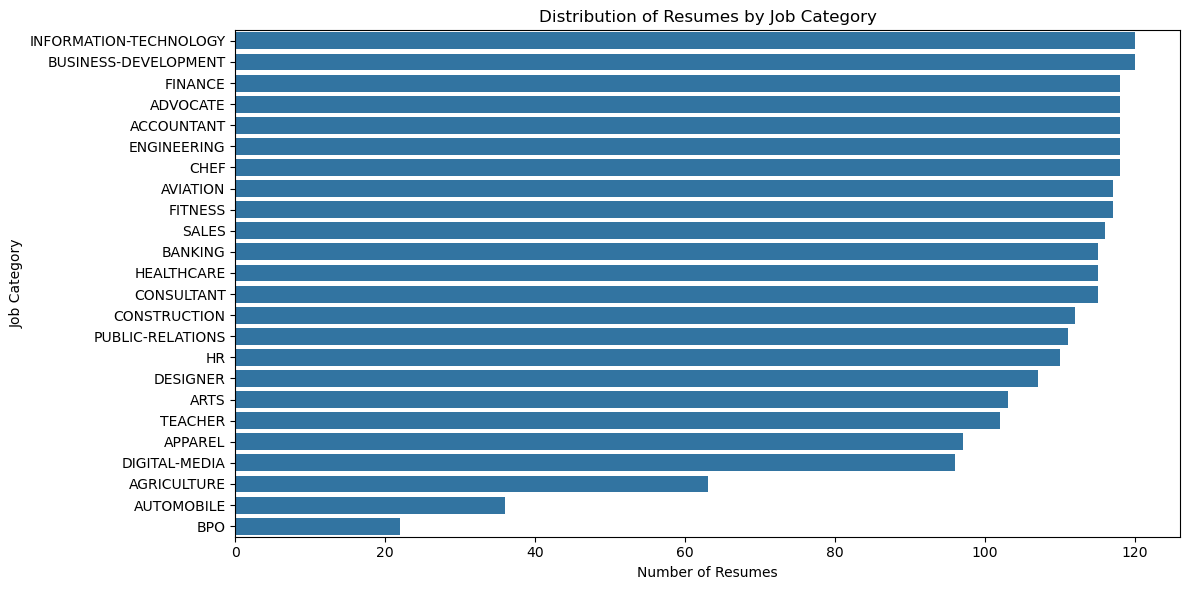

In [4]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='Category',
    order=df['Category'].value_counts().index
)

plt.title("Distribution of Resumes by Job Category")
plt.xlabel("Number of Resumes")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


In [5]:

import re
import html

def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Decode HTML entities
    text = html.unescape(text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Keep letters, numbers and technical symbols
    text = re.sub(r'[^a-zA-Z0-9+#.\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


# Apply cleaning to resume text
df['Cleaned_Resume'] = df['Resume_str'].apply(clean_text)

print("Resume text cleaning completed!")

print("\nOriginal Resume:")
print(df['Resume_str'].iloc[0][:500])

print("\nCleaned Resume:")
print(df['Cleaned_Resume'].iloc[0][:500])


Resume text cleaning completed!

Original Resume:
         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-task

Cleaned Resume:
hr administrator marketing associate hr administrator summary dedicated customer service manager with 15+ years of experience in hospitality and customer service management. respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service. highlights focused on customer satisfaction team management marketing savvy conflict resolution techniques training and developmen

In [6]:

print("Total Resumes:", len(df))

print("Empty Cleaned Resumes:",
      (df['Cleaned_Resume'].str.len() == 0).sum())

print("\nSample Cleaned Data:")
df[['ID', 'Category', 'Cleaned_Resume']].head()


Total Resumes: 2484
Empty Cleaned Resumes: 1

Sample Cleaned Data:


,ID,Category,Cleaned_Resume
0,16852973,HR,hr administrator marketing associate hr admini...
1,22323967,HR,hr specialist us hr operations summary versati...
2,33176873,HR,hr director summary over 20 years experience i...
3,27018550,HR,hr specialist summary dedicated driven and dyn...
4,17812897,HR,hr manager skill highlights hr skills hr depar...


In [7]:

# Remove resumes with empty cleaned text

df = df[df['Cleaned_Resume'].str.strip() != ''].copy()

df.reset_index(drop=True, inplace=True)

print("Empty resumes removed successfully!")
print("Remaining resumes:", len(df))
print("Empty resumes:",
      (df['Cleaned_Resume'].str.len() == 0).sum())


Empty resumes removed successfully!
Remaining resumes: 2483
Empty resumes: 0


In [8]:

# Skills database

skills_list = [
    'python', 'java', 'c++', 'c#', 'sql',
    'machine learning', 'deep learning',
    'artificial intelligence', 'data science',
    'data analysis', 'data visualization',
    'natural language processing', 'nlp',
    'tensorflow', 'pytorch', 'keras',
    'scikit-learn', 'pandas', 'numpy',
    'matplotlib', 'seaborn',
    'excel', 'power bi', 'tableau',
    'html', 'css', 'javascript',
    'react', 'node.js', 'flask', 'django',
    'mongodb', 'mysql', 'postgresql',
    'aws', 'azure', 'google cloud',
    'docker', 'kubernetes', 'git',
    'communication', 'leadership',
    'project management', 'problem solving',
    'recruitment', 'talent acquisition',
    'human resources', 'payroll',
    'marketing', 'sales', 'accounting',
    'financial analysis'
]

print("Total skills in database:", len(skills_list))


Total skills in database: 52


In [9]:

def extract_skills(text):

    found_skills = []

    text = text.lower()

    for skill in skills_list:

        pattern = r'(?<!\w)' + re.escape(skill) + r'(?!\w)'

        if re.search(pattern, text):
            found_skills.append(skill)

    return found_skills


# Apply skill extraction
df['Extracted_Skills'] = df['Cleaned_Resume'].apply(extract_skills)

# Count extracted skills
df['Skill_Count'] = df['Extracted_Skills'].apply(len)

print("Skill extraction completed!")

df[['ID', 'Category', 'Extracted_Skills', 'Skill_Count']].head(10)


Skill extraction completed!


,ID,Category,Extracted_Skills,Skill_Count
0,16852973,HR,"[data analysis, leadership, human resources, p...",7
1,22323967,HR,"[communication, project management, recruitmen...",6
2,33176873,HR,"[excel, leadership, project management, recrui...",7
3,27018550,HR,"[excel, communication, payroll]",3
4,17812897,HR,"[excel, leadership, project management, proble...",7
5,11592605,HR,"[excel, recruitment, human resources]",3
6,25824789,HR,"[leadership, project management, human resources]",3
7,15375009,HR,"[communication, project management, recruitmen...",5
8,11847784,HR,"[excel, communication, leadership, project man...",5
9,32896934,HR,"[recruitment, human resources, payroll, accoun...",4


In [10]:

from collections import Counter

all_skills = []

for skills in df['Extracted_Skills']:
    all_skills.extend(skills)

skill_counts = Counter(all_skills)

top_skills = pd.DataFrame(
    skill_counts.most_common(15),
    columns=['Skill', 'Count']
)

print("Top 15 Most Common Skills:")
display(top_skills)


Top 15 Most Common Skills:


,Skill,Count
0,sales,1311
1,communication,1297
2,leadership,1026
3,excel,960
4,marketing,870
5,accounting,560
6,project management,556
7,problem solving,510
8,payroll,441
9,human resources,283


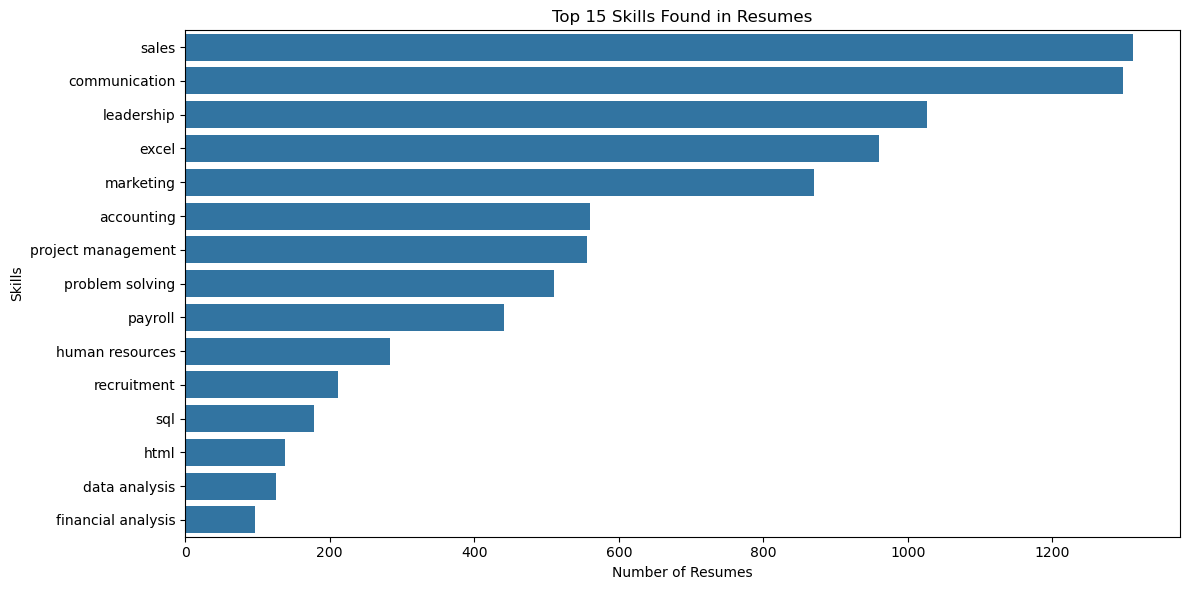

In [11]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_skills,
    x='Count',
    y='Skill'
)

plt.title("Top 15 Skills Found in Resumes")
plt.xlabel("Number of Resumes")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()


In [12]:

job_role = "Machine Learning Engineer"

job_description = """
We are looking for a Machine Learning Engineer
with strong knowledge of Python, SQL, Machine Learning,
Deep Learning, Natural Language Processing,
Data Science, Pandas, NumPy, TensorFlow,
PyTorch, Scikit-learn and Data Analysis.

Candidates should have experience in model development,
data preprocessing, data visualization,
problem solving and communication.
"""

# Extract required skills from job description
required_skills = extract_skills(job_description)

print("Target Job Role:", job_role)
print("\nRequired Skills:")
print(required_skills)
print("\nTotal Required Skills:", len(required_skills))


Target Job Role: Machine Learning Engineer

Required Skills:
['python', 'sql', 'machine learning', 'deep learning', 'data science', 'data analysis', 'data visualization', 'natural language processing', 'tensorflow', 'pytorch', 'scikit-learn', 'pandas', 'numpy', 'communication', 'problem solving']

Total Required Skills: 15


In [13]:

# Combine resumes and job description
documents = df['Cleaned_Resume'].tolist() + [
    clean_text(job_description)
]

# Create TF-IDF vectors
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(documents)

# Separate resume vectors and job description vector
resume_vectors = tfidf_matrix[:-1]
job_vector = tfidf_matrix[-1]

print("TF-IDF model created successfully!")
print("Resume vectors shape:", resume_vectors.shape)
print("Job description vector shape:", job_vector.shape)


TF-IDF model created successfully!
Resume vectors shape: (2483, 10000)
Job description vector shape: (1, 10000)


In [14]:

# Calculate cosine similarity
similarity_scores = cosine_similarity(
    resume_vectors,
    job_vector
).flatten()

# Convert similarity into percentage
df['Similarity_Score'] = similarity_scores * 100

print("Similarity calculation completed!")
print(df[['ID', 'Category', 'Similarity_Score']].head())


Similarity calculation completed!
         ID Category  Similarity_Score
0  16852973       HR          2.568489
1  22323967       HR          0.793719
2  33176873       HR          1.282633
3  27018550       HR          0.262892
4  17812897       HR          1.222120


In [15]:

def calculate_skill_match(candidate_skills):
    if len(required_skills) == 0:
        return 0

    matched = set(candidate_skills).intersection(
        set(required_skills)
    )

    return (len(matched) / len(required_skills)) * 100


df['Skill_Match_Score'] = df['Extracted_Skills'].apply(
    calculate_skill_match
)

df['Final_Score'] = (
    0.70 * df['Similarity_Score'] +
    0.30 * df['Skill_Match_Score']
)

print("Final scoring completed!")


Final scoring completed!


In [16]:

# Sort candidates by final score
ranked_candidates = df.sort_values(
    by='Final_Score',
    ascending=False
).copy()

ranked_candidates.reset_index(drop=True, inplace=True)

ranked_candidates['Rank'] = (
    ranked_candidates.index + 1
)

# Display top 10 candidates
display(
    ranked_candidates[
        ['Rank', 'ID', 'Category',
         'Similarity_Score',
         'Skill_Match_Score',
         'Final_Score']
    ].head(10)
)


,Rank,ID,Category,Similarity_Score,Skill_Match_Score,Final_Score
0,1,12011623,ENGINEERING,31.333460,40.000000,33.933422
1,2,21156767,CONSULTANT,29.901841,40.000000,32.931289
2,3,18448085,AUTOMOBILE,19.951397,53.333333,29.965978
3,4,62994611,AGRICULTURE,18.110007,40.000000,24.677005
4,5,34953092,BANKING,25.309388,20.000000,23.716572
5,6,12351749,SALES,21.084084,26.666667,22.758859
6,7,22946204,AUTOMOBILE,18.927346,26.666667,21.249142
7,8,11813872,AGRICULTURE,16.093628,26.666667,19.265540
8,9,28505854,ENGINEERING,18.773735,13.333333,17.141614
9,10,18067556,INFORMATION-TECHNOLOGY,14.683128,20.000000,16.278190


In [17]:

def get_missing_skills(candidate_skills):
    matched = set(candidate_skills).intersection(
        set(required_skills)
    )

    missing = set(required_skills) - matched

    return list(missing)


ranked_candidates['Matched_Skills'] = (
    ranked_candidates['Extracted_Skills'].apply(
        lambda x: list(set(x).intersection(set(required_skills)))
    )
)

ranked_candidates['Missing_Skills'] = (
    ranked_candidates['Extracted_Skills'].apply(
        get_missing_skills
    )
)

# Display top 5 candidates with skill gaps
display(
    ranked_candidates[
        ['Rank', 'ID', 'Final_Score',
         'Matched_Skills', 'Missing_Skills']
    ].head(5)
)


,Rank,ID,Final_Score,Matched_Skills,Missing_Skills
0,1,12011623,33.933422,"[data visualization, sql, pandas, machine lear...","[numpy, pytorch, data science, tensorflow, nat..."
1,2,21156767,32.931289,"[data visualization, sql, machine learning, da...","[numpy, pytorch, pandas, tensorflow, natural l..."
2,3,18448085,29.965978,"[numpy, data visualization, sql, pandas, data ...","[pytorch, machine learning, tensorflow, commun..."
3,4,62994611,24.677005,"[data visualization, sql, pandas, tensorflow, ...","[numpy, pytorch, machine learning, data scienc..."
4,5,34953092,23.716572,"[python, sql, machine learning]","[numpy, data visualization, pytorch, pandas, d..."


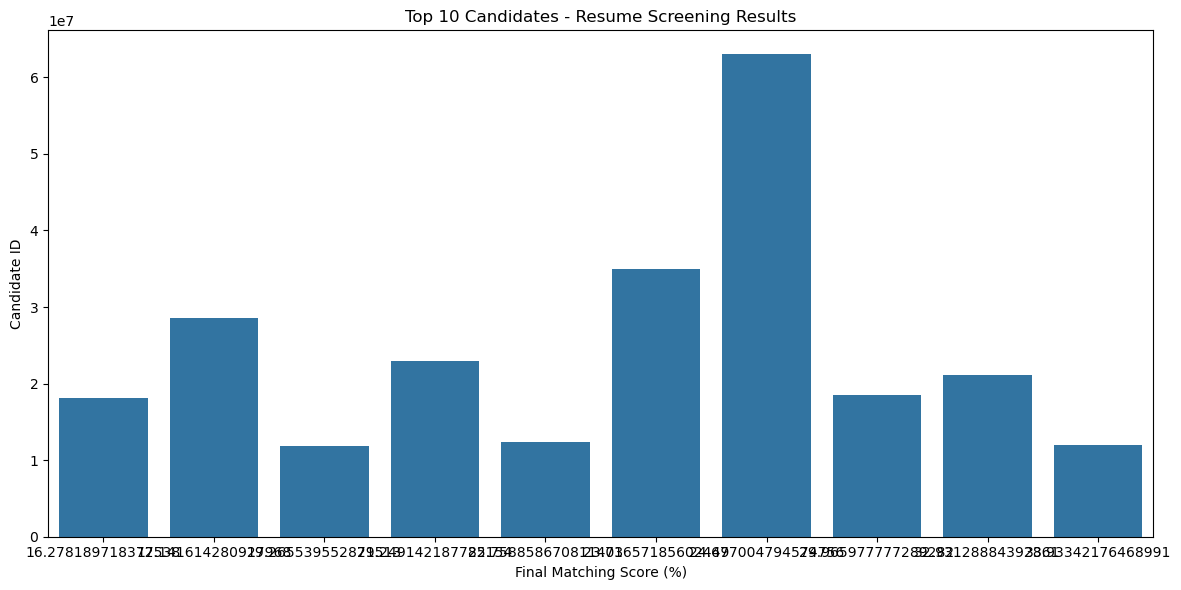

In [18]:

top_10 = ranked_candidates.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x='Final_Score',
    y='ID'
)

plt.title('Top 10 Candidates - Resume Screening Results')
plt.xlabel('Final Matching Score (%)')
plt.ylabel('Candidate ID')
plt.tight_layout()
plt.show()


In [21]:

# Save only important columns instead of complete resume text

columns_to_save = [
    'Rank',
    'ID',
    'Category',
    'Similarity_Score',
    'Skill_Match_Score',
    'Final_Score',
    'Matched_Skills',
    'Missing_Skills'
]

ranked_candidates[columns_to_save].to_csv(
    '../outputs/candidate_ranking.csv',
    index=False
)

ranked_candidates[columns_to_save].head(10).to_csv(
    '../outputs/top_10_candidates.csv',
    index=False
)

print("Smaller CSV files saved successfully!")


Smaller CSV files saved successfully!


In [22]:

best_candidate = ranked_candidates.iloc[0]

print("=" * 55)
print("       RESUME SCREENING REPORT")
print("=" * 55)

print("Job Role:", job_role)
print("Total Resumes Screened:", len(df))

print("\nTOP RANKED CANDIDATE")
print("Candidate ID:", best_candidate['ID'])
print("Category:", best_candidate['Category'])

print("Final Score:",
      round(best_candidate['Final_Score'], 2), "%")

print("\nMatched Skills:")
print(best_candidate['Matched_Skills'])

print("\nMissing Skills:")
print(best_candidate['Missing_Skills'])

print("=" * 55)


       RESUME SCREENING REPORT
Job Role: Machine Learning Engineer
Total Resumes Screened: 2483

TOP RANKED CANDIDATE
Candidate ID: 12011623
Category: ENGINEERING
Final Score: 33.93 %

Matched Skills:
['data visualization', 'sql', 'pandas', 'machine learning', 'python', 'data analysis']

Missing Skills:
['numpy', 'pytorch', 'data science', 'tensorflow', 'natural language processing', 'communication', 'deep learning', 'scikit-learn', 'problem solving']
